# Antenna positions for HERA

This notebook plots the positions of the 350 HERA antennas in different coordinate frames.

In [1]:
import numpy as np
import sys, glob, os, time
from astropy import cosmology, units, constants
import pyuvdata
from scipy import interpolate

In [2]:
import matplotlib.pyplot as plt
from matplotlib import rc, colors, cm

In [3]:
rc("font", **{"family": "serif", "serif": ["times new roman"], "size": 15})
rc("text", usetex=True)
rc("axes", linewidth=1.5)

In [4]:
%matplotlib inline
%load_ext autoreload
%autoreload 2

In [5]:
pyuvdata.__version__

'3.2.1'

In [9]:
hera = pyuvdata.Telescope.from_known_telescopes('HERA')
nantennas = np.max(hera.antenna_numbers)+1
print(f'{np.max(hera.antenna_numbers)+1} antennas.')

350 antennas.


### Array layout

In [10]:
hera_antpos_ENU = hera.get_enu_antpos() # ENU
hera_antpos_ECEF = pyuvdata.utils.ECEF_from_ENU(hera_antpos_ENU, center_loc=hera.location)
hera_antpos_long, hera_antpos_lat, hera_antpos_alt = pyuvdata.utils.LatLonAlt_from_XYZ(hera_antpos_ECEF)  # radians
telescope_location = hera.location_lat_lon_alt_degrees * units.deg

In [11]:
telescope_location

<Quantity [ -30.72152612,   21.42830383, 1051.69      ] deg>

In [12]:
array_centre_long, array_centre_lat = -30.72142, 21.4281

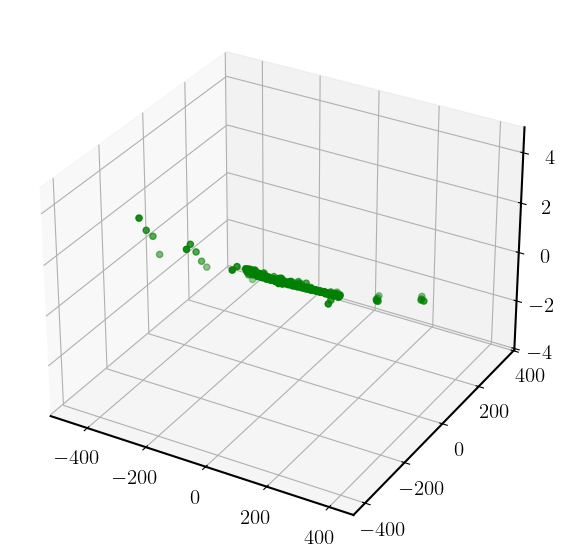

In [13]:
fig = plt.figure(figsize = (10, 7))
ax = plt.axes(projection ="3d")
ax.scatter3D(hera_antpos_ENU[:, 0], hera_antpos_ENU[:, 1], hera_antpos_ENU[:, 2], color = "green")

Text(0.5, 0.92, 'In geocentric frame')

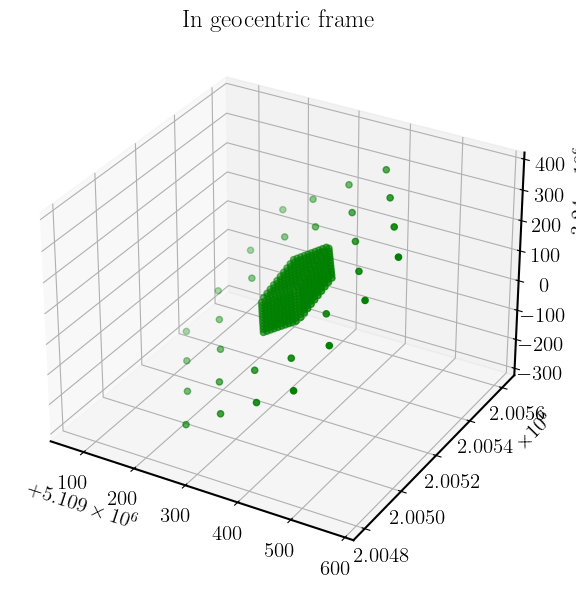

In [14]:
fig = plt.figure(figsize = (10, 7))
ax = plt.axes(projection ="3d")
ax.scatter3D(hera_antpos_ECEF[:, 0], hera_antpos_ECEF[:, 1], hera_antpos_ECEF[:, 2], color = "green")
ax.set_title('In geocentric frame')

0.005031938187853413
0.0037314748841801304 None


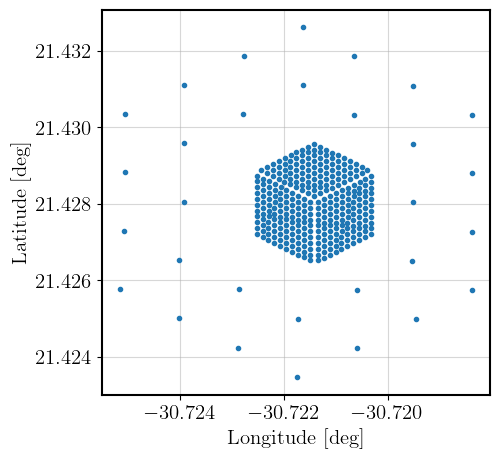

In [11]:
fig, ax = plt.subplots(figsize=(5, 5))
plt.plot(hera_antpos_long*180./np.pi, hera_antpos_lat*180./np.pi, '.')
ax.set_xlabel(r'Longitude [deg]')
ax.set_ylabel('Latitude [deg]')
ax.grid(visible=True, alpha=0.5)
print(np.diff(ax.get_xbound())[0]/2., print(np.diff(ax.get_ybound())[0]/2.))


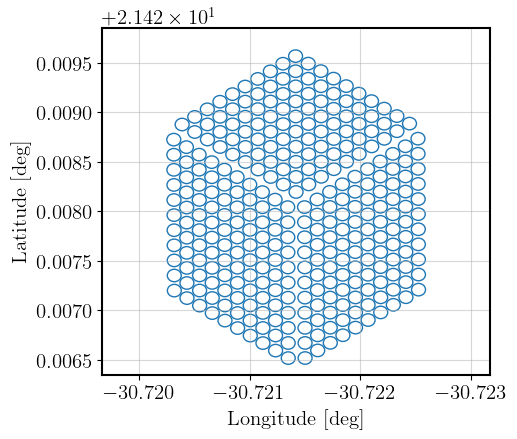

In [12]:
# zoom on the core

antenna_width = hera.antenna_diameters[0] * units.m  # m
antenna_angle = antenna_width / constants.R_earth.si  # rad
width = 0.0035

fig, ax = plt.subplots(figsize=(5, 4.5))
# plt.scatter(hera_antpos_long*180./np.pi, hera_antpos_lat*180./np.pi, marker='.')
for i in range(nantennas):
    ax.add_patch(plt.Circle([hera_antpos_long[i]*180./np.pi, hera_antpos_lat[i]*180./np.pi], radius=antenna_angle*180/np.pi/2., fc='none', ec='C0'))
ax.set_xlabel(r'Longitude [deg]')
ax.set_ylabel('Latitude [deg]')
x1, y1 = np.array([array_centre_long, array_centre_lat]) - width/2.
x2, y2 = np.array([array_centre_long, array_centre_lat]) + width/2.
# plt.scatter(array_centre_long, array_centre_lat, marker='+')
ax.set_xlim(x2, x1)
ax.set_ylim(y1, y2)
ax.grid(visible=True, alpha=0.5)
